# Issue #369 — corrected N7 support-shape factorial

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/n7_support_shape'

In [2]:
dev=pd.read_csv(OUT/'development_score_summary.csv'); dev

,base,diagnostic,conditioning,rows,mean_score,observed_rate,bin_spearman,nonnegative_monotonicity
0,R0_CORRECTED,contraction_score,SUPPORTED_REALIZED,1427,0.707281,0.710582,0.705170,True
1,R0_CORRECTED,expansion_score,ALL,1781,0.166266,0.198765,0.911858,True
2,R3_CORRECTED,contraction_score,SUPPORTED_REALIZED,1410,0.721945,0.718440,0.826752,True
3,R3_CORRECTED,expansion_score,ALL,1781,0.185926,0.208310,0.866667,True


In [3]:
perf=pd.read_csv(OUT/'performance.csv'); perf[perf.scope.eq('ALL')]

,scope,base,shape,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,hit_rate,conditional_gross_on_hit_cny,ex_largest_pnl_cny
24,ALL,R0_CORRECTED,BOTH,151,154624.0,135140.485377,-19483.514623,80516.485377,-0.194835,-0.126006,0.211921,4223.140168,-36219.815495
25,ALL,R0_CORRECTED,CONTRACTION_ONLY,151,154624.0,171307.328805,16683.328805,116683.328805,0.166833,0.107896,0.198675,5710.244294,-5973.072356
26,ALL,R0_CORRECTED,CONTROL,151,154624.0,138630.058770,-15993.941230,84006.058770,-0.159939,-0.103438,0.258278,3554.616892,-28175.681483
27,ALL,R0_CORRECTED,EXPANSION_ONLY,151,154624.0,126696.766173,-27927.233827,72072.766173,-0.279272,-0.180614,0.298013,2815.483693,-35783.384262
28,ALL,R3_CORRECTED,BOTH,151,154624.0,225509.721873,70885.721873,170885.721873,0.708857,0.458439,0.198675,7516.990729,21630.981034
29,ALL,R3_CORRECTED,CONTRACTION_ONLY,151,154624.0,170614.638344,15990.638344,115990.638344,0.159906,0.103416,0.125828,8979.717808,-19949.995657
30,ALL,R3_CORRECTED,CONTROL,151,154624.0,187313.126230,32689.126230,132689.126230,0.326891,0.211410,0.172185,7204.351009,-27225.255881
31,ALL,R3_CORRECTED,EXPANSION_ONLY,151,154624.0,185691.221445,31067.221445,131067.221445,0.310672,0.200921,0.258278,4761.313370,-13612.565138


In [4]:
risk=pd.read_csv(OUT/'risk_diagnostics.csv'); risk[risk.scope.eq('ALL')]

,scope,base,shape,max_drawdown_fraction,longest_losing_run,open_underwater_issues,largest_payout_share,payout_hhi
24,ALL,R0_CORRECTED,BOTH,0.626510,16,146,0.131421,0.051714
25,ALL,R0_CORRECTED,CONTRACTION_ONLY,0.484987,16,0,0.138233,0.053319
26,ALL,R0_CORRECTED,CONTROL,0.302304,14,151,0.095259,0.042020
27,ALL,R0_CORRECTED,EXPANSION_ONLY,0.475534,14,151,0.070090,0.034548
28,ALL,R3_CORRECTED,BOTH,0.329055,22,0,0.222956,0.091388
29,ALL,R3_CORRECTED,CONTRACTION_ONLY,0.500756,31,1,0.216656,0.097748
30,ALL,R3_CORRECTED,CONTROL,0.331650,19,1,0.325329,0.136820
31,ALL,R3_CORRECTED,EXPANSION_ONLY,0.342635,17,1,0.246128,0.098786


In [5]:
contrasts=pd.read_csv(OUT/'bootstrap.csv'); contrasts[contrasts.scope.eq('ALL')]

,scope,contrast,issues,matched_lift_cny,ideal_fractional_matched_lift_cny,integer_contribution_to_lift_cny,largest_abs_delta_issue,largest_abs_delta_cny,ex_largest_lift_cny,bootstrap_p05_cny,bootstrap_median_cny,bootstrap_p95_cny,ideal_bootstrap_p05_cny,ideal_bootstrap_median_cny,ideal_bootstrap_p95_cny
36,ALL,R0_CORRECTED:CONTRACTION_MAIN,151,32677.270036,32677.270036,0.000000,22095,-13205.740252,45883.010288,-14889.294246,33361.237547,78059.848468,-14889.294246,33361.237547,78059.848468
37,ALL,R0_CORRECTED:EXPANSION_MAIN,151,-11933.292596,-14005.708640,2072.416044,23104,7313.689825,-19246.982421,-37766.577821,-12415.731235,15846.269557,-39982.448939,-14723.073232,14563.956802
38,ALL,R0_CORRECTED:BOTH_V_CONTROL,151,-3489.573393,-6504.842133,3015.268740,22095,-13205.740252,9716.166859,-45934.367894,-3076.381302,36351.942094,-49063.196539,-5842.903374,33700.819325
39,ALL,R0_CORRECTED:FACTORIAL_INTERACTION,151,-24233.550833,-25176.403529,942.852696,23104,-7313.689825,-16919.861007,-50376.168245,-23905.600305,1592.717588,-53362.885179,-24679.489240,1744.703685
40,ALL,R3_CORRECTED:CONTRACTION_MAIN,151,-16698.487885,-16698.487885,0.000000,23021,-60938.382111,44239.894226,-140073.006099,-9881.808126,79355.860709,-140073.006099,-9881.808126,79355.860709
41,ALL,R3_CORRECTED:EXPANSION_MAIN,151,-1621.904784,-9199.015996,7577.111212,24104,25139.370419,-26761.275204,-52134.394782,-2984.015304,56594.871450,-63461.113555,-9042.262375,48292.052649
42,ALL,R3_CORRECTED:BOTH_V_CONTROL,151,38196.595643,24644.392739,13552.202904,23021,-60938.382111,99134.977754,-115247.286645,40407.132772,173511.773028,-124458.335104,27851.417522,150121.298164
43,ALL,R3_CORRECTED:FACTORIAL_INTERACTION,151,56516.988313,50541.896621,5975.091692,24104,25139.370419,31377.617893,6575.536690,54205.546653,117151.422152,141.089056,48309.728293,111032.539200
44,ALL,R3_MINUS_R0:CONTROL,151,48683.067460,48683.067460,0.000000,23021,60938.382111,-12255.314651,-58206.863145,40407.385388,177357.172206,-58206.863145,40407.385388,177357.172206
45,ALL,R3_MINUS_R0:CONTRACTION_ONLY,151,-692.690461,-692.690461,0.000000,24081,36964.634002,-37657.324463,-95824.998806,-1680.016650,103473.626278,-95824.998806,-1680.016650,103473.626278


In [6]:
integer=pd.read_csv(OUT/'integer_allocation_effect.csv'); integer[integer.scope.eq('ALL')]

,scope,base,shape,issues,integer_pnl_cny,ideal_fractional_pnl_cny,integer_minus_ideal_cny
24,ALL,R0_CORRECTED,BOTH,151,-19483.514623,-22498.783364,3015.268740
25,ALL,R0_CORRECTED,CONTRACTION_ONLY,151,16683.328805,16683.328805,0.000000
26,ALL,R0_CORRECTED,CONTROL,151,-15993.941230,-15993.941230,0.000000
27,ALL,R0_CORRECTED,EXPANSION_ONLY,151,-27927.233827,-29999.649870,2072.416044
28,ALL,R3_CORRECTED,BOTH,151,70885.721873,57333.518969,13552.202904
29,ALL,R3_CORRECTED,CONTRACTION_ONLY,151,15990.638344,15990.638344,0.000000
30,ALL,R3_CORRECTED,CONTROL,151,32689.126230,32689.126230,0.000000
31,ALL,R3_CORRECTED,EXPANSION_ONLY,151,31067.221445,23490.110233,7577.111212


In [7]:
admission=pd.read_csv(OUT/'expert_admission.csv'); admission

,base,shape,standalone_positive,standalone_ex_largest_positive,matched_lift_positive,matched_ex_largest_positive,bootstrap_p05_nonnegative,at_least_two_positive_annual_lifts,admitted
0,R0_CORRECTED,CONTRACTION_ONLY,True,False,True,True,False,True,False
1,R0_CORRECTED,EXPANSION_ONLY,False,False,False,False,False,False,False
2,R0_CORRECTED,BOTH,False,False,False,True,False,False,False
3,R3_CORRECTED,CONTRACTION_ONLY,True,False,False,True,False,True,False
4,R3_CORRECTED,EXPANSION_ONLY,True,False,False,False,False,True,False
5,R3_CORRECTED,BOTH,True,True,True,True,False,True,False


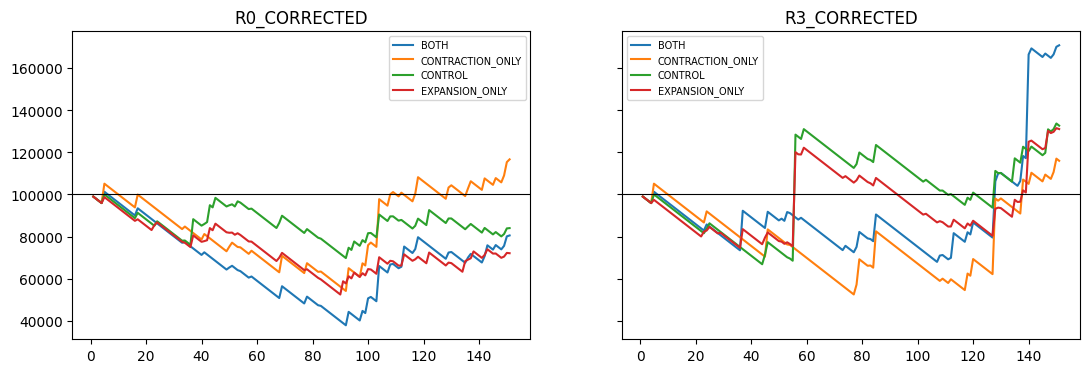

In [8]:
paths=pd.read_csv(OUT/'capital_paths.csv')
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,(base,g) in zip(axes,paths[paths.scope.eq('ALL')].groupby('base')):
    for shape,s in g.groupby('shape'): ax.plot(s.issue_order,s.capital_cny,label=shape)
    ax.axhline(100000,color='black',lw=.8); ax.set_title(base); ax.legend(fontsize=7)
plt.show()